## Упражнения


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from scipy.fft import fft
np.random.seed(0)

### Упражнение 1

- Рассмотрим в качестве сезонной составляющей периодический сигнал с периодом 12
```python
time = np.arange(144)
seasonal_12 = 20 + np.sin(2*np.pi*time/12)*20
```
- Используйте `seasonal_12` и компоненты `trend` и `residual` ниже, чтобы определить и построить аддитивную и мультипликативную модели
```python
trend = time * 2.65 + 100
residuals = np.random.normal(loc=0.0, scale=3, size=len(time))
```
- Выполните сезонную декомпозицию с `seasonal_decompose` и `STL` для новых сигналов и сравните результаты с полученными в классе, где мы использовали приблизительный период.

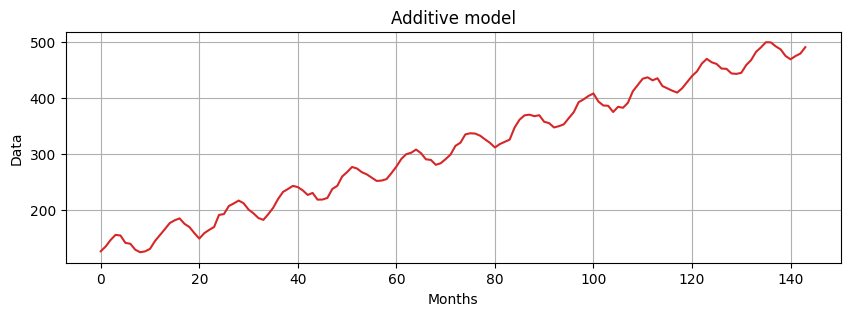

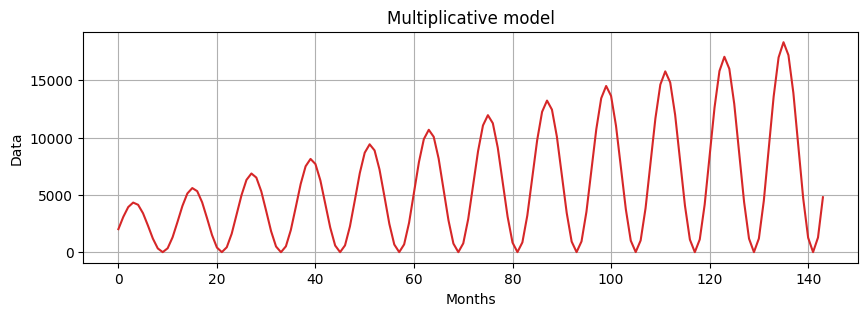

In [6]:
time = np.arange(144)
seasonal_12 = 20 + np.sin(2*np.pi*time/12)*20
trend = time * 2.65 + 100
residuals = np.random.normal(loc=0.0, scale=3, size=len(time))

additive = trend + seasonal_12 + residuals
multiplicative = trend * seasonal_12 + residuals

fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.plot(time, additive, color='tab:red')
ax.set_xlabel("Months")
ax.set_ylabel("Data")
plt.title("Additive model");
plt.grid()


fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.plot(time, multiplicative, color='tab:red')
ax.set_xlabel("Months")
ax.set_ylabel("Data")
plt.title("Multiplicative model");
plt.grid()

In [9]:
# метод вывода графиков
def seas_decomp_plots(original, decomposition):
    _, axes = plt.subplots(4, 1, sharex=True, sharey=False, figsize=(7, 5))
    axes[0].plot(original, label='Original')
    axes[0].legend(loc='upper left')
    axes[1].plot(decomposition.trend, label='Trend')
    axes[1].legend(loc='upper left')
    axes[2].plot(decomposition.seasonal, label='Seasonality')
    axes[2].legend(loc='upper left')
    axes[3].plot(decomposition.resid, label='Residuals')
    axes[3].legend(loc='upper left')
    plt.show()

In [10]:
# декомпозиция аддитивной модели
additive_decomposition_sea = seasonal_decompose(additive, model='additive', period=12)
additive_decomposition_STL = STL(additive, period=12, robust=True).fit()

Декомпозиция seasonal_decompose:


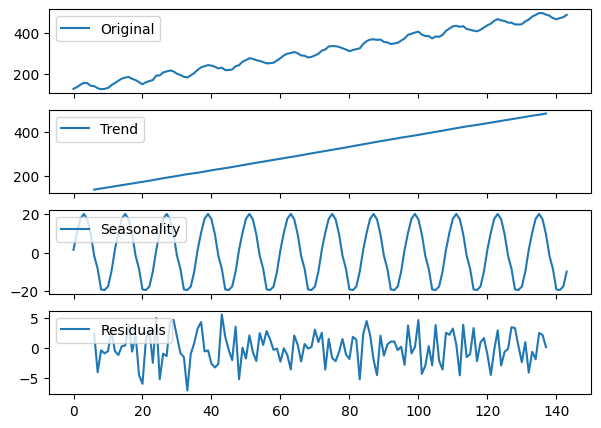




Декомпозиция STL:


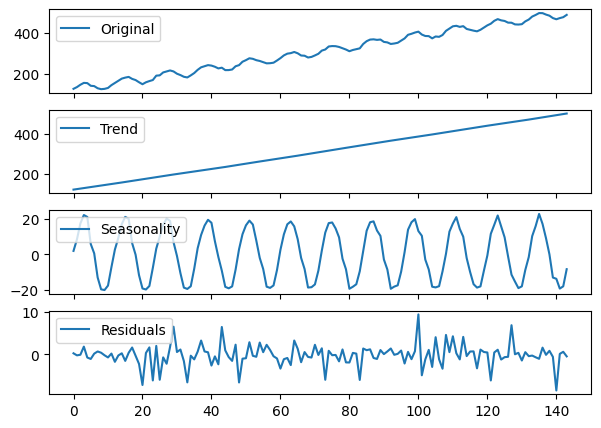

In [11]:
print("Декомпозиция seasonal_decompose:")
seas_decomp_plots(additive, additive_decomposition_sea)

print("\n\n\nДекомпозиция STL:")
seas_decomp_plots(additive, additive_decomposition_STL)

Оба способа декомпозиции показали примерно одинаковые разложения на компоненты.

### Упражнение 2
Загрузите два разных временных ряда следующим образом.
```python
import statsmodels.api as sm
ts_A = sm.datasets.get_rdataset("AirPassengers", "datasets").data["value"].values
print(len(ts_A))
ts_B = sm.datasets.get_rdataset("co2", "datasets").data["value"].values
print(len(ts_B))
```
- Постройте график двух временных рядов.
- Определите, выглядит ли временной ряд аддитивной или мультипликативной моделью.
- Определите основной период сезонной составляющей в двух временных рядах.

In [14]:
import statsmodels.api as sm
ts_A = sm.datasets.get_rdataset("AirPassengers", "datasets").data["value"].values
print(len(ts_A))
data = sm.datasets.co2.load_pandas().data
ts_B = data['co2'].dropna().values
print(len(ts_B))

144
2225


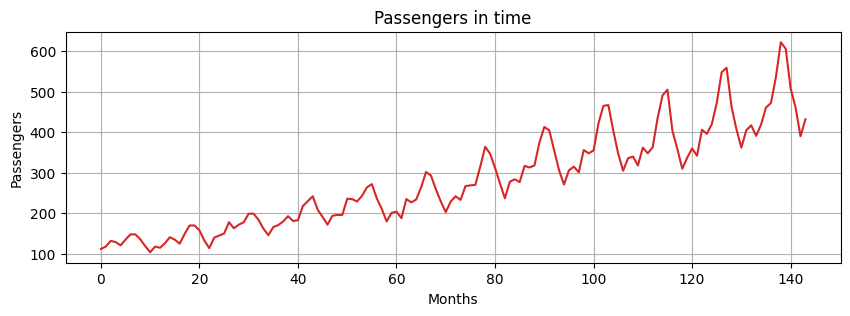

In [15]:
time = np.arange(len(ts_A))
fig, ax = plt.subplots(1,1, figsize=(10,3))
ax.plot(time, ts_A,color='tab:red')
ax.set_xlabel("Months")
ax.set_ylabel("Passengers")
plt.grid()
plt.title("Passengers in time");

Ряд похож на мультипликативную модель, т.к. видно увеличение амплитуды сезонной компоненты, значит она умножается на увеличивающийся тренд. Период - 12

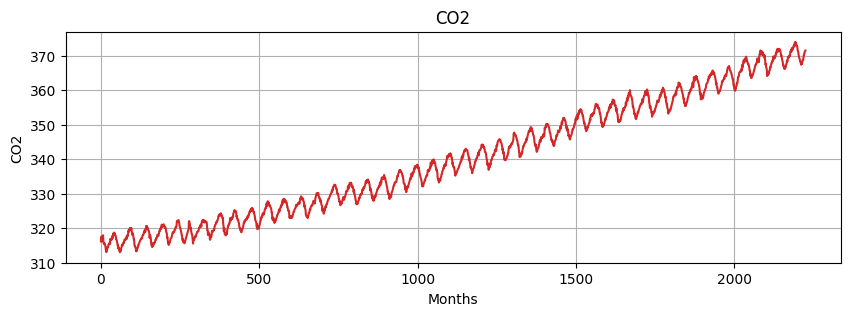

In [16]:
time = np.arange(len(ts_B))
fig, ax = plt.subplots(1,1, figsize=(10,3))
ax.plot(time, ts_B,color='tab:red')
ax.set_xlabel("Months")
ax.set_ylabel("CO2")
plt.grid()
plt.title("CO2");

Ряд похож на аддитивную модель, т.к. видна неизменность амплитуды сезонной компоненты, значит она складывается с трендом. Период вроде в районе 50, судя по аргументу - временной шкале.

### Упражнение 3
- Разложите `ts_A` и `ts_B` с помощью `seasonal_decompose` и `STL`.
- Прокомментируйте полученные результаты.
from statsmodels.tsa.seasonal import season_decompose, STL

In [19]:
# декомпозиция ts_A через мультипликативность
multiplicative_decomposition_sea = seasonal_decompose(ts_A, model='multiplicative', period=12)
multiplicative_decomposition_STL = STL(ts_A, period=12, robust=True).fit()

Декомпозиция seasonal_decompose:


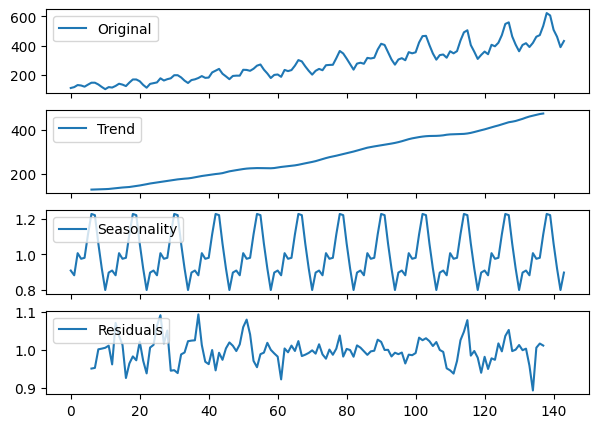




Декомпозиция STL:


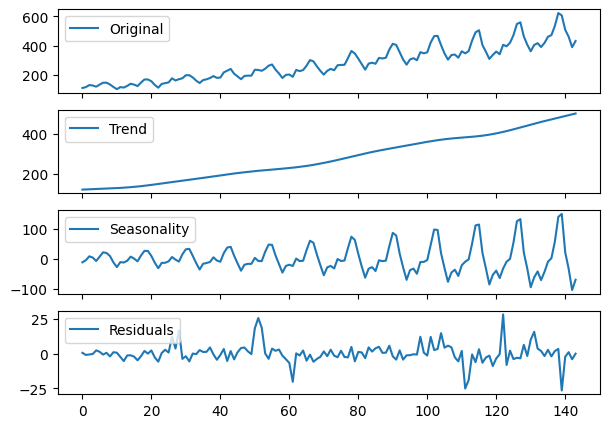

In [20]:
print("Декомпозиция seasonal_decompose:")
seas_decomp_plots(ts_A, multiplicative_decomposition_sea)

print("\n\n\nДекомпозиция STL:")
seas_decomp_plots(ts_A, multiplicative_decomposition_STL)

Метод seasonal_decompose правильно разложил ряд на компоненты. STL показал некорректную сезонную компоненту, т.к. данный метод не предназначен для мультипликативных моделей.

In [21]:
# декомпозиция ts_B через аддитивность
additive_decomposition_sea = seasonal_decompose(ts_B, model='additive', period=50)
additive_decomposition_STL = STL(ts_B, period=50, robust=True).fit()

Декомпозиция seasonal_decompose:


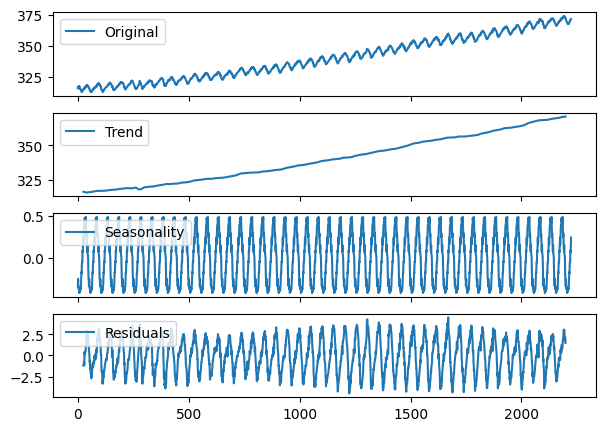




Декомпозиция STL:


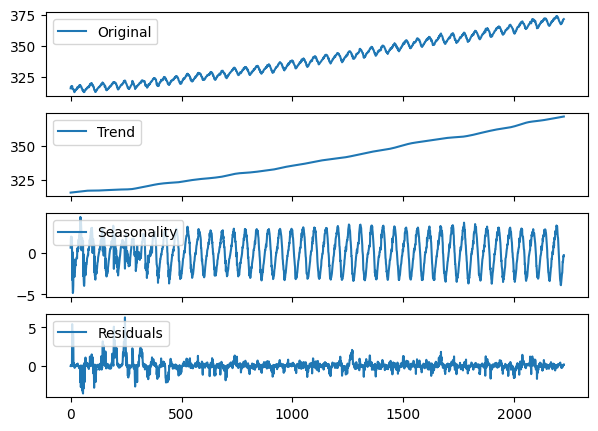

In [22]:
print("Декомпозиция seasonal_decompose:")
seas_decomp_plots(ts_B, additive_decomposition_sea)

print("\n\n\nДекомпозиция STL:")
seas_decomp_plots(ts_B, additive_decomposition_STL)

Оба метода декомпозиции хорошо справились с розложением ряда на компоненты.